# Lesson 11. Why a distant bar takes up fewer pixels

[Course plan](../../README.md)

The previous drawing put a vertex one meter to the right and four meters in front of the camera. A photograph still needs an address inside the frame. A ray through the point meets a little grid in front of the camera. Its crossing tells us which part of the image the point occupies.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. One meter at different distances

The blue bar measures exactly one meter. It lies $y=0.5$ m below the optical axis. On the left, rays run from the camera to the middle and ends of the bar in an overhead view. The right-hand image has 201 columns and 121 rows. At a depth of 4 m and a focal length of 80 pixels the bar spans 20 pixel intervals. At 2 m it spans 40. With focal length fixed, it is the ratio of width to depth that changes.

The green line in the overhead view lies 0.2 m in front of the camera. As the camera approaches the object the bar first goes beyond the frame and is eventually clipped in depth. These two disappearances have different causes that show up in the numbers.

In [2]:
display(demos.geometry_lab(11, "en"))

The purple bar is also one metre long, but its world depth stays at 8 m. It sits half a metre above the optical axis and therefore appears above the blue bar in the image. This gives us a second object in the same exposure. Two camera settings can agree on every point of the blue bar and still be distinguishable by that distant object.

## 2. Which distance counts as depth?

The previous lesson left us with a vertex in the camera frame. We have its displacement from the lens and the length of that displacement. Why would the image scale depend on just the third component? One end of the blue bar lies at $(0.5,0.5,4)$ m and the other at $(1.5,0.5,4)$ m. Their distances from the origin are $\sqrt{0.25+0.25+16}\approx4.06$ m and $\sqrt{2.25+0.25+16}\approx4.30$ m. Yet both lie on the same plane, four metres **forward** of the camera. Forward progress is what determines where the rays intersect another plane parallel to this one. Both points get the same scale factor.

In a physical pinhole camera the light continues through the tiny aperture and meets a sensor behind it, forming an inverted image. For the drawing we use a virtual plane in front of the aperture instead. It intersects the same straight lines on the object's side. An object on the right now lands at the right of the drawing, and positive $y$ still leads down the image. This choice already includes the change of side. An extra minus sign on $x$ would flip the picture sideways.

## 3. Where the ray meets the plane

The ray starts at the camera center $(0,0,0)$. The middle of the bar lies at $P=(1,0.5,4)$ m. Traveling from camera to point scales the three distances by the same factor. A quarter of the way gives $(1/4,0.5/4,4/4)=(0.25,0.125,1)$ m. The last number is now 1. This is where the ray meets an imaginary plane one meter in front of the camera. The doubled point $(2,1,8)$ meets that plane at exactly the same place. A single pixel leaves an entire ray of possible depths.

In general the camera point is $(x,y,z)$. Dividing all three components by $z$ makes the last component 1. The two plane coordinates that remain are $x/z$ and $y/z$. They are ratios of meters to meters and have no unit. The same sideways meter takes up a smaller fraction of a distant point's depth. Division applies for $z>0$. At zero the ray generally has no finite intersection with the image plane. Behind the camera, at $z<0$, the extension of the line points the opposite way.

In [3]:
p = np.array([1., .5, 4.])
print("P / z =", p/p[2], "    2P / (2z) =", (2*p)/(2*p[2]))
assert np.allclose(p[:2]/p[2], (2*p)[:2]/(2*p[2]))

P / z = [0.25  0.125 1.   ]     2P / (2z) = [0.25  0.125 1.   ]


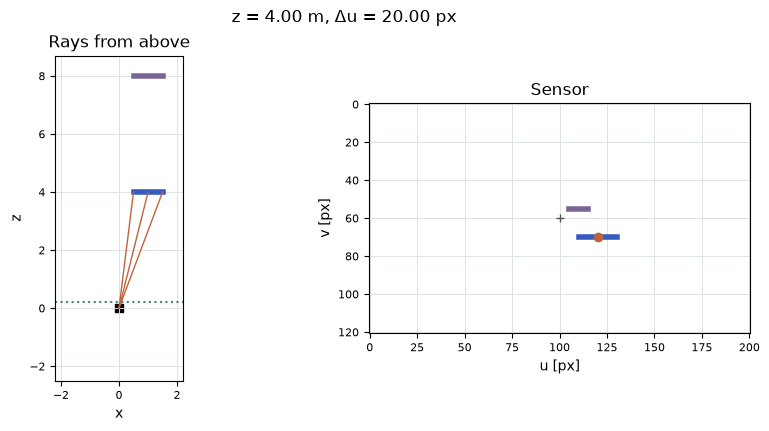

In [4]:
fig = demos.perspective_figure("en")
plt.show()

## 4. How pixels got into the numerator

Suppose a very small piece of film receives the image. Its virtual plane is 4 mm from the aperture, and the middle of the bar has a sideways-to-forward ratio $x/z=1/4$. Its ray crosses the film $4\cdot1/4=1$ mm from center. The aperture, bar and ray make two similar triangles: going from four metres of depth to four millimetres scales the sideways length by the same factor of one thousand. A point one metre off to the side in the scene is now only a millimetre off to the side on the film.

Suppose twenty pixel intervals fit in a millimetre. One horizontal interval is $1/20=0.05$ mm wide, so that millimetre spans $1/0.05=20$ intervals. We could just as well divide the aperture-to-film distance by the grid spacing in advance: $4/0.05=80$. This is the **focal length in pixels**, $f_x=80$ px. It corresponds to 4 mm only for the stated pixel spacing. A figure of “80 pixels” alone does not recover the physical focal length.

The vertical grid can be finer. At a pitch of 0.04 mm the same lens gives $f_y=4/0.04=100$ px. Since $y/z=0.5/4=0.125$, the displacement is $100\cdot0.125=12.5$ pixels down. Half a pixel is a perfectly good position on the continuous plane. Writing to an array eventually requires integer row indices. A Gaussian center will keep its fractional position so nearby pixels receive distinct weights around the true center. Rounding that center before computing weights would make a drifting splat jump from one whole interval to the next.

## 5. From a ratio to a pixel address

We have measured a direction. Now it needs a scale. A focal length $f_x=80$ pixels means that one unit of $x/z$ becomes 80 horizontal pixel intervals. In this experiment $f_y=80$ vertically as well. For example, $x/z=0.25$ gives $80\cdot0.25=20$ pixels to the right of the optical axis. The downward shift is $80\cdot0.125=10$ pixels.

For image width $W=201$, column centers are numbered 0 through 200, so the middle index is $c_x=(W-1)/2=100$. Height $H=121$ gives $c_y=60$. The pair is the principal point, where the optical axis meets the image. Real calibration estimates its location separately and can place it off center. Pixel centers sit at integer coordinates, but a geometric ray can hit between them. The calculation keeps fractional coordinates until an operation actually needs an integer address.

$$
\begin{aligned}
u&=c_x+f_x\,x/z=100+80\cdot1/4=120,\\
v&=c_y+f_y\,y/z=60+80\cdot0.5/4=70.
\end{aligned}
$$

Here $u$ increases rightward and $v$ downward. The left tip of the bar has $x=0.5$ and therefore $u=110$. The right tip has $x=1.5$ and $u=130$. Subtracting gives $130-110=20$ pixel intervals of length. Coloring every integer center including both endpoints would touch 21 centers. Geometric length and the number of touched centers measure different things.

In [5]:
principal = (100, 60)
for x in [.5, 1, 1.5]:
    print(f"x={x:g} m →", geo.project_point([x,.5,4], 80, principal, near=.2), "px")
np.testing.assert_allclose(geo.project_point(p, (80,100), principal), [120,72.5])

x=0.5 m → [110.  70.] px
x=1 m → [120.  70.] px
x=1.5 m → [130.  70.] px


## 6. Cropping the frame with the camera still

In our original image the optical axis meets the sensor at $(100,60)$. This is the **principal point**, where the direction $(0,0,1)$ lands. Suppose 30 columns are removed from the left and ten rows from the top. The camera hasn't moved, so the world rays stay the same. Column zero of the new array used to be column 30. Every old address therefore loses $(30,10)$. The middle of the bar moves from $(120,70)$ to $(90,60)$ in array coordinates. The principal point also moves, to $(70,50)$. The difference $(90-70,60-50)=(20,10)$ is unchanged. Cropping alone has left the focal length in pixels intact.

A change in resolution behaves differently. For a simple example, the new array keeps only the even rows and columns, starting at zero. Old column 120 becomes column 60 and column 100 becomes column 50. Their difference is now just ten. Pixel spacing has doubled, so the numbers $f_x,f_y$ are halved. Our point now lands at $u'=50+40\cdot1/4=60$ and $v'=30+40\cdot0.5/4=35$. This rule follows from a particular alignment of pixel centers. A resizing tool that aligns pixel edges rather than the centers of the even columns introduces a fractional-pixel shift. Following two known addresses through the actual operation reveals the new scale and offset.

A training set might come with a camera calibrated for the original photographs but use smaller images for speed. If the frames are halved and the old focal length is left in the camera, a splat with nonzero $x$ lands too far from the new principal point. A centered splat cannot expose the mistake: both the old and the new factor multiply zero. Objects near the edges reveal it much more clearly. A single splat dead center is a weak calibration test.

Now we can measure how much of a scene fits in the frame. From the principal point to the center of the rightmost pixel in the original frame there are exactly 100 intervals. At $f_x=80$ that edge ray has slope $x/z=100/80=1.25$. Four metres forward it crosses the wall at $x=5$ m. The left edge is symmetric, so ten metres of wall fit between the centers of the two outer pixels. With the same array and $f_x=160$ that span drops to five metres. Keeping every other pixel instead halves both the distance to the outer center and the focal length in pixels. Their ratio $50/40$ is still $1.25$. The same wall fits in the frame, sampled at half the horizontal density.

In [6]:
p = np.array([1., .5, 4.])
uv = geo.project_point(p, 80, (100,60))
print("original", uv, " crop", uv-[30,10], " half", uv/2)
np.testing.assert_allclose(geo.project_point(p,80,(70,50)), uv-[30,10])
np.testing.assert_allclose(geo.project_point(p,40,(50,30)), uv/2)
np.testing.assert_allclose(geo.project_point(p,(80,100),(100,60)), [120,72.5])

original [120.  70.]  crop [90. 60.]  half [60. 35.]


## 7. The same steps in matrix form

The two focal lengths and the principal point fit into one matrix $K$. Its top row multiplies $f_x x$ and $c_x z$, then sums the products. The bottom row passes depth through untouched:

$$
K\begin{bmatrix}x\\y\\z\end{bmatrix}
=\begin{bmatrix}80&0&100\\0&80&60\\0&0&1\end{bmatrix}
\begin{bmatrix}1\\0.5\\4\end{bmatrix}
=\begin{bmatrix}80+400\\40+240\\4\end{bmatrix}
=\begin{bmatrix}480\\280\\4\end{bmatrix}.
$$

The first two entries still have units of pixels times meters. The last entry is depth in meters. Dividing by it gives the same address $(480/4,280/4)=(120,70)$ px. If the point starts in the world, $B^{\mathsf T}(P-C)$ from the previous lesson goes into $K$ first.

The camera moves 2 m forward. The world point stays put, but its depth is now $4-2=2$. The middle lands at $(140,80)$ px and the length of the bar is $80\cdot1/2=40$ px. A 160 px focal length from the old camera position produces the same result for **this** bar. For a second object at depth 8 m, moving 2 m forward enlarges it only by a factor of $8/6$. Doubling focal length enlarges both objects by two. This difference in relative size distinguishes camera motion from a change of focal length.

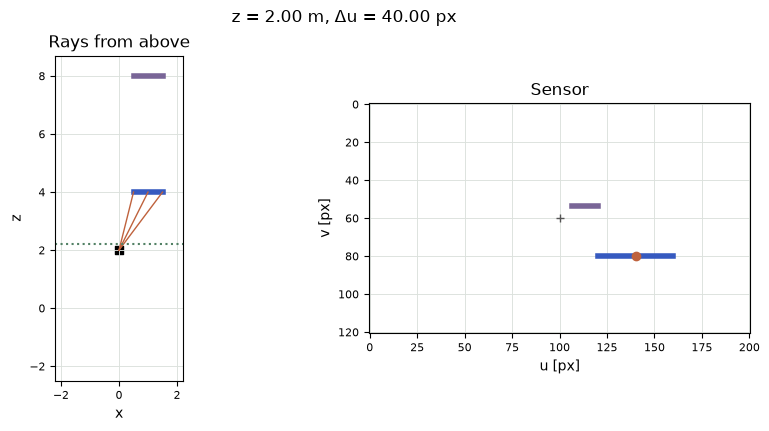

In [7]:
fig = demos.perspective_figure("en", camera_z=2)
plt.show()

In [8]:
K = np.array([[80, 0, 100], [0, 80, 60], [0, 0, 1]])
h = K @ p
print("Kp =", h, "   (u, v) =", h[:2]/h[2])
for z in [4, 8]:
    print(f"z={z}: move → {80/(z-2):.2f} px; zoom → {160/z:.2f} px")

Kp = [480. 280.   4.]    (u, v) = [120.  70.]
z=4: move → 40.00 px; zoom → 40.00 px
z=8: move → 13.33 px; zoom → 20.00 px


## 8. Two pictures with exactly the same foreground

Three frames can now share a horizontal ruler. In the original view the blue bar spans 20 pixel intervals. In the second view the camera moves forward, reducing its depth from four metres to two. In the third view the distance stays the same but the focal length becomes 160 pixels. The second and third setups match not just in blue-bar width but in both screen coordinates of its midpoint. Adding any number of further points on that particular foreground plane would not distinguish them. Each setup gives the plane the same factor $f/z=40$ pixels per metre.

Now the background bar gets a vote. For that purple bar the factor started at $80/8=10$. Moving the camera gives $80/(8-2)\approx13.33$, while changing the lens gives $160/8=20$. The ratio of foreground to background width started at $20/10=2$. After moving the camera it becomes $40/13.33\approx3$. Changing focal length leaves it at $40/20=2$, just as in the original. A forward camera move enlarges a nearby object more strongly. A longer focal length enlarges both by the same factor about the principal point. A single object on a single depth plane would have made the cause of enlargement easy to misidentify.

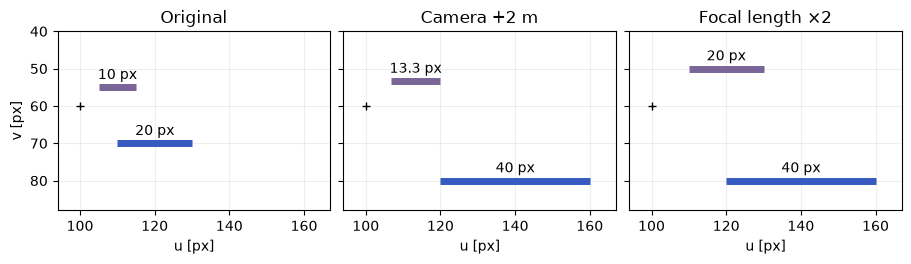

In [9]:
fig, panels = plt.subplots(1, 3, figsize=(9, 3.0), sharex=True, sharey=True, layout="constrained")
titles = ["Original", "Camera +2 m", "Focal length ×2"]
for ax, title, (focal, advance) in zip(panels,titles,[(80,0),(80,2),(160,0)]):
    for y, z, color in [(.5,4,demos.BLUE), (-.5,8,"#796597")]:
        ends = np.array([geo.project_point([x,y,z-advance], focal, (100,60)) for x in [.5,1.5]])
        ax.plot(*ends.T, color=color, lw=5, solid_capstyle="butt")
        width = ends[1,0]-ends[0,0]
        label = f"{width:.1f}".rstrip("0").rstrip(".") + " px"
        ax.annotate(label, ends.mean(0), xytext=(0,6), textcoords="offset points", ha="center")
    ax.plot(100,60,"+", color="black")
    ax.set(xlim=(94,167), ylim=(88,40), aspect="equal", title=title, xlabel="u [px]")
    ax.grid(alpha=.2)
panels[0].set_ylabel("v [px]")
plt.show()

## 9. Two ways to lose a point

For $z=0.5$ m and $x=1$ m the ray still points forward, but $u=100+80/0.5=260$ is already beyond the right edge. At $z=0.2$ a different rule applies. This scene keeps depths **strictly greater** than 0.2 m. The near plane protects against huge values close to division by zero. A line segment with endpoints on opposite sides needs geometric clipping. Our bar is parallel to the sensor, so its endpoints pass or fail together.

**An experiment.** We know pixel $(120,70)$ and focal length 80 but have lost the depth. Which two different points could have produced it?

<details>
<summary>Working it out</summary>

Subtracting principal point $(100,60)$ from the address leaves $(20,10)$. Division by 80 gives the direction $(0.25,0.125,1)$. Multiplying by any positive depth gives a point on the ray. Depths 2 and 4 give $(0.5,0.25,2)$ and $(1,0.5,4)$ m.

</details>

**At the edge.** With $f_x=80$ and $z=4$, which world $x$ lands exactly in the middle of the last column?

<details>
<summary>Working it out</summary>

The camera is at the world origin and the axes agree. The last column has $u=200$. The offset from the center is $200-100=100$ px. The ratio $x/z=100/80=1.25$, so $x=4\cdot1.25=5$ m. The sensor edge itself lies another half pixel beyond this column's center.

</details>

The convention for $K$ and the world-to-camera transformation appears in [OpenCV's pinhole camera model](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html).

## 10. Giving a pixel its depth back

One address gives two ratios, $x/z$ and $y/z$. It has no independent reading of $z$. Two different additions to our experiment can supply that missing length. In the first, the bar has a known size. It lies parallel to the sensor, its image spans 20 pixel intervals, and there is exactly one metre between the ends. We found $\Delta u=f_x L/z$ for its horizontal length $L$ in metres. Multiplying both sides by $z$, then dividing by the nonzero $\Delta u$, gives $z=f_x L/\Delta u=80\cdot1/20=4$ m. If the bar tilts so its ends have different depths, a single denominator no longer describes them both. The image width alone does not tell us the new angle.

In the second experiment the object's size is unknown. There is another camera, shifted exactly $0.8$ m to the right, with parallel axes, the same focal length and the same principal point. The bar's midpoint had $x=1$ m in the first camera. It lies just $1-0.8=0.2$ m to the right of the second one. At a depth of 4 m the new address is $100+80\cdot0.2/4=104$, against 120 in the first exposure. Their difference $d=120-104=16$ pixels is called **disparity**. The horizontal separation of the cameras is the baseline, here $b=0.8$ m. Subtracting the addresses cancels the principal points and the unknown world $x$:

$$
\begin{aligned}
u_L-u_R
&=\left(c_x+f_x\frac{x}{z}\right)-
  \left(c_x+f_x\frac{x-b}{z}\right)\\
&=\frac{f_x}{z}\bigl(x-(x-b)\bigr)
=\frac{f_x b}{z}.
\end{aligned}
$$

Now $z=f_x b/d=80\cdot0.8/16=4$ m. The denominator must be positive for this camera arrangement and this subtraction order. At zero baseline any depth gives zero difference: a second exposure at the same position has added no information. For a very distant object the difference is small, and a single pixel of error is expensive. At $d=4$ the depth is $64/4=16$ m, but at $d=3$ it is already $64/3\approx21.33$ m. The marks in the two views must belong to the **same detail**. A convincing but incorrect match gives a perfectly definite number for a ray that belongs elsewhere.

**Two grids.** The point $(1,0.5,4)$ landed at $(120,72.5)$. The principal point is $(100,60)$. Which horizontal and vertical focal lengths explain it?

<details>
<summary>Worked answer</summary>

The horizontal offset of 20 px divided by $1/4$ gives 80 px. The vertical offset of 12.5 px divided by $0.5/4$ gives 100 px. With different pixel pitches these can be readings of the same physical lens. A single point on the optical axis would give neither focal length this way.
</details>

**A cropped frame.** Someone left the principal point at $(100,60)$ after the crop. Where will the prediction land relative to the measured mark?

<details>
<summary>Worked answer</summary>

The relative shift $20,10$ stays the same. The incorrect camera predicts $(120,70)$ in the new array, while the mark has moved to $(90,60)$. The error is 30 columns to the right and ten rows down, the same for other points. A focal-length error would instead produce a shift that varies across the image.
</details>

**Checking a distant point.** The distant mark has an eight-column disparity. The mark in the right camera was accidentally picked one column farther right. Which way will the reconstructed depth move?

<details>
<summary>Worked answer</summary>

The right address increases by one so the former disparity of eight drops to seven. Instead of $64/8=8$ m the estimate becomes $64/7\approx9.14$ m. The object looks farther away. Only one mark changed; both camera equations stayed the same.
</details>